# **Practical Assignment 2**
# **Team: Minnie, Fran**
## Introduction
In this assignment, it is expected that you explore autoencoders in reconstruction and denoising tasks, and exploit an object detector network with real world data. This assignment is split into two parts: image reconstruction and object detection. This assignment should be done in groups of 2 students, and it is part of your continuous evaluation. You should provide a report, with no more than 10 pages, and a notebook (.ipynb) which includes your development and analysis for the requested tasks. Structure your report in accordance with the assignment parts.


[Part 1](#scrollTo=Dt16hNk1i88M)


[Part 2](#scrollTo=8Zv1I2XJj_GK)


# Assignment 2 Part 1
# **Reconstruction and denoising using Autoencoders**
1. Implement an AE network (the network of the first assignment can be a good starting point); You can use a fully-connected-based encoder-decoder, however a convolution-based encoder-decoder will be valued.  
2.  Modify the encoder, add the reparameterization trick and add the VAE loss to the aforementioned network;
3.  Implement the DAE’s pipeline;
4.  Implement the aforementioned evaluation metrics to evaluate your network;
5.  Gather the metrics and loss curves for all training conditions.
6.  Use t-SNE (t-distributed Stochastic Neighbor Embedding) to visualize the bottleneck/latent space of the AE, VAE and DAE.
7.  Apply transfer learning using the encoder layer of the AE, VAE and DAE. Add a classification layer to all the encoders (individual), freeze the encoder layer and only train the classification layer. Compare the classification results obtained, and how well the learned representations generalize.


1. Initial Configuration

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
import numpy as np
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import os
import random

# ---------------------- 0. SETUP ----------------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Semilla
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print("Seed fixed in:", SEED)

# Hiperparámetros globales (adapted batch_size to 100 for similarity)
batch_size = 100
latent_dim = 32     # dimensión del espacio latente
epochs_ae = 20
epochs_vae = 20
epochs_dae = 20
epochs_clf = 20     # épocas para el clasificador de transfer learning
lr = 1e-3         # learning rate para Adam
noise_factor = 0.5      # intensidad del ruido para el DAE
beta_kl = 1.0         # peso del término de KL en el VAE

Using device: cuda
Seed fixed in: 42


2. Set up Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

save_dir = "/content/drive/MyDrive/modelos_entrenados"
os.makedirs(save_dir, exist_ok=True)  # crea la carpeta si no existe

print("Safe here:", save_dir)

Safe here: /content/drive/MyDrive/modelos_entrenados


3. Loading the Dataset: Kuzushiji-MNIST

In [ ]:
# ---------------------- 1. DATASET ----------------------
# Kuzushiji-MNIST, same as Assignment 1
transform = transforms.Compose([
    transforms.ToTensor(),  # [0,1]           # pasa las imágenes de PIL/numpy a tensores torch y normaliza a [0, 1]
])

train_dataset = datasets.KMNIST(root='./data', train=True, download=True, transform=transform)        # 60k training
test_dataset = datasets.KMNIST(root='./data', train=False, download=True, transform=transform)        # 10k test

# # Split train into train/val (90%/10%)
# val_size = len(train_dataset) // 10
# train_size = len(train_dataset) - val_size
# train_ds, val_ds = random_split(train_dataset, [train_size, val_size])

# ---- Split train into train/val (15% validación) ----
val_ratio = 0.15
n_train  = len(train_dataset)
n_val    = int(n_train * val_ratio)
n_tr     = n_train - n_val

split_generator = torch.Generator().manual_seed(SEED)
train_ds, val_ds = random_split(
    train_dataset, [n_tr, n_val], generator=split_generator
)

train_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_ds, batch_size=batch_size, shuffle=True, generator=train_generator
)
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)                 # val_loader y test_loader sin barajar (no hace falta para evaluar)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

100%|██████████| 18.2M/18.2M [00:08<00:00, 2.09MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 278kB/s]
100%|██████████| 3.04M/3.04M [00:01<00:00, 2.55MB/s]
100%|██████████| 5.12k/5.12k [00:00<00:00, 14.4MB/s]


In [ ]:
# KMNIST: 60k train, 10k test → 51k train, 9k val, 10k test

4. Models: AE, VAE, DAE (Convolutional)

In [ ]:
# ---------------------- 2. MODELOS ----------------------
class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        # Encoder (similar to CNN in Assignment 1)
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1),  # 28x28
            nn.ReLU(),                      # introduce no linealidad
            nn.MaxPool2d(2, 2),  # 14x14
            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 7x7
        )
        self.fc_mu = nn.Linear(32*7*7, latent_dim)          # cuello de botella (bottleneck) --> en lugar de aplanar lo pasamos a un vector latente para aprovechar el espacio 2D

        # Decoder
        self.fc_dec = nn.Linear(latent_dim, 32*7*7)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2),  # 14x14
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=2, stride=2),   # 28x28
            nn.Sigmoid()        # valores en [0,1], coherente con las imágenes de entrada
        )

    def encode(self, x):
        h = self.encoder(x)         # (B, 32, 7, 7)
        h = h.view(h.size(0), -1)     # (B, 32*7*7)
        z = self.fc_mu(h)        # (B, latent_dim)
        return z                  # z es tu representación latente (bottleneck)

    def decode(self, z):
        h = self.fc_dec(z)        # vector de tamaño 32*7*7
        h = h.view(-1, 32, 7, 7)        # lo conviertes en “pequeña imagen” de características
        out = self.decoder(h)         # upsampling
        return out

    def forward(self, x):         # forward devuelve dos cosas: la reconstrucción recon y el latente z
        z = self.encode(x)
        recon = self.decode(z)
        return recon, z

class ConvVAE(ConvAutoencoder):       # hereda de AE pero añade una segunda capa lineal fc_logvar que produce el log-variance de la distribución latente.
    def __init__(self, latent_dim):
        super().__init__(latent_dim)
        self.fc_logvar = nn.Linear(32*7*7, latent_dim)

    def encode(self, x):            # El encoder del VAE ahora devuelve dos cosas: mu (media de la gaussiana latente), logvar (log-varianza (para estabilidad numérica))
        h = self.encoder(x)
        h = h.view(h.size(0), -1)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar, generator=None):     # para convertir tanto mu como logvar en un único vector latente (z)
        std = torch.exp(0.5 * logvar)         # std = e^0.5*log(std^2)
        eps = torch.randn(
            std.shape, dtype=std.dtype, device=std.device, generator=generator
        )
        return mu + eps * std         # fórmula impuesta en la tarea para calcular z en VAE

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        return recon, mu, logvar, z       # el fordward del VAE devuelve la imagen reconstruida, mu, logvar y el vector latente --> La pérdida de VAE (más abajo) combina: 1. pérdida de reconstrucción, 2. pérdida KL (para que la distrib. se acerque a N(0,1)).

ConvDAE = ConvAutoencoder  # Alias for DAE --> DAE tiene la misma estructura que AE

5.  Utilities

In [ ]:
# ---------------------- 3. UTILIDADES ----------------------
def add_noise(x, noise_factor=0.5, generator=None):
    noise = noise_factor * torch.randn(
        x.shape, dtype=x.dtype, device=x.device, generator=generator
    )
    noisy_x = x + noise
    return torch.clamp(noisy_x, 0., 1.)       # Suma a la imagen y recorta a [0,1]

# MSE por pixel y no por imagen
def compute_loss_ae(recon, x):
    # MSE por píxel (media sobre todas las imágenes y todos los píxeles)
    batch_size = x.size(0)          # tamaño del batch (B)
    num_pixels_per_image = x[0].numel()   # cuenta cuántos valores tiene una imagen: C*H*W --> (Si son imágenes 1×28×28 ⇒ 784 píxeles)
    mse_sum = nn.functional.mse_loss(recon, x, reduction='sum')     # Calcula la suma del error cuadrático sobre todos los píxeles del batch --> Si tienes batch de tamaño B y cada imagen tiene 28x28, hace la suma sobre B * 28 * 28
    # media por píxel
    return mse_sum / (batch_size * num_pixels_per_image)      # no solo lo dividimos por el tamaño del batch (que sería a nivel de imagen) sino que lo multiplicamos por num_pixel para que sea la pérdida a nivel de pixel por batch

# Si dejas el KL “por imagen” y la reconstrucción “por píxel”, el término KL dominará la pérdida del VAE
def compute_kl_divergence(mu, logvar, num_pixels_per_image=28*28):        # En el VAE el encoder no da un vector fijo, sino una distribución N(μ, σ²) --> La fórmula es el KL-divergence entre esa distribución y una normal estándar N(0, I)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())            # fórmula impuesta por la práctica para calcular el KL
    batch_size = mu.size(0)
    # KL por píxel (igual escala que el MSE de reconstrucción)
    return kl / (batch_size * num_pixels_per_image)

# Evaluation function adapted from Assignment 1 for classifiers  --> para entrenar el clasificador (Transfer Learning)
def evaluate_model(model, loader, device):
    model.eval()
    y_true = []
    y_pred = []
    with torch.no_grad():
        for data, target in loader:
            data, target = data.to(device), target.to(device)
            output = model(data)        # saca los loggits del modelo --> logits [B, 10]
            pred = output.argmax(dim=1, keepdim=True)     # las predicciones (argmax(dim=1) → índice de la clase más probable para cada ejemplo)
            y_true.extend(target.cpu().numpy())         # extiende la lista con los valores en numpy de los targets reales
            y_pred.extend(pred.cpu().numpy().flatten())       # lo mismo con las predicciones
    y_true = np.array(y_true)   # convierte la lista entera en un array numpy para poder calcular posteriormente las métricas
    y_pred = np.array(y_pred)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    mCA = np.mean([accuracy_score(y_true[y_true==i], y_pred[y_true==i]) for i in np.unique(y_true)] if len(np.unique(y_true)) > 0 else 0)       # Para cada clase i, compute accuracy solo en esa clase, y luego haces la media --> Es útil cuando las clases están desbalanceadas
    cm = confusion_matrix(y_true, y_pred)
    return {'acc': acc, 'prec': prec, 'rec': rec, 'f1': f1, 'mCA': mCA, 'cm': cm}

# Training functions
def train_one_epoch_ae(model, loader, optimizer, is_dae=False):
    model.train()
    total_loss = 0
    for data, _ in loader:     # data son las imágenes, _ ignora las etiquetas (no se usan en reconstrucción)
        data = data.to(device)        # Se mandan a device (CPU/GPU)
        if is_dae:        # si is_dae=True:
            data_noisy = add_noise(data, noise_factor)        # se le añade ruido al data
            recon, _ = model(data_noisy)          # cogemos solamente la imagen reconstruida (recuerda que fordward de AE, DAE te da (recon, z))
            loss = compute_loss_ae(recon, data)     # esto se calcula igual que AE porque tienen la misma estructura (solo cambia que le meten ruido)
        else:         # is_dae=False y por tanto queremos entrenar "ae"
            recon, _ = model(data)
            loss = compute_loss_ae(recon, data)
        # Paso típico de backprop:
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # Se hace esto porque no todos los batch del dataset son los mismos --> el ultimo no suele coincidir con el número fijo
        total_loss += loss.item() * data.size(0)      # loss.item() es el MSE medio por píxel en ese batch, data.size(0) = B (tamaño del batch) --> entonces ya no estamos calculando el MSE por pixel a nivel de batch sino el MSE por pixel a nivel de imagen
    return total_loss / len(loader.dataset)     # dividmos por el total de imagenes para obtener --> MSE media por píxel en todo el dataset

def train_one_epoch_vae(model, loader, optimizer):      # para entrenar VAE
    model.train()
    total_loss = total_recon = total_kl = 0
    for data, _ in loader:
        data = data.to(device)
        recon, mu, logvar, _ = model(data)
        recon_loss = compute_loss_ae(recon, data)                   # MSE por píxel
        # kl_loss = compute_kl_divergence(mu, logvar)
        num_pixels_per_image = data[0].numel()
        kl_loss = compute_kl_divergence(mu, logvar, num_pixels_per_image=num_pixels_per_image)        # para calcular KL a nivel de píxel y no a nivel de imagen por batch
        loss = recon_loss + beta_kl * kl_loss         # beta pondera kl_loss --> Si beta es grande → latentes más “bonitos” pero peor reconstrucción, Si beta es pequeño → mejor reconstrucción pero latente menos estructurado
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * data.size(0)                # total_loss → suma de (recon + β KL) * batch_size sobre todos los batches
        total_recon += recon_loss.item() * data.size(0)             # total_recon → suma de solo recon_loss * batch_size
        total_kl += kl_loss.item() * data.size(0)
    n = len(loader.dataset)
    return (total_loss / n, total_recon / n, total_kl / n)

    # Al final divido todo entre n (número de imágenes del dataset) y obtengo:
        # loss media por imagen (pero en unidad “pérdida por píxel”, porque dentro ya se había hecho la división).
        # recon media por píxel.
        # kl media por píxel.

def validate(model, loader, is_vae=False, is_dae=False):      # Validación
    model.eval()
    total_loss = 0
    # Mismo ruido en cada época: las pérdidas de validación son comparables.
    eval_generator = torch.Generator(device=device).manual_seed(SEED)
    with torch.no_grad():
        for data, _ in loader:
            data = data.to(device)
            if is_dae:            # sino es dae entonces es AE y entra en else
                data_noisy = add_noise(data, noise_factor, generator=eval_generator)
                recon, _ = model(data_noisy)
                loss = compute_loss_ae(recon, data)
            elif is_vae:
                mu, logvar = model.encode(data)
                z = model.reparameterize(mu, logvar, generator=eval_generator)
                recon = model.decode(z)
                recon_loss = compute_loss_ae(recon, data)
                # kl_loss = compute_kl_divergence(mu, logvar)
                num_pixels_per_image = data[0].numel()
                kl_loss = compute_kl_divergence(mu, logvar, num_pixels_per_image=num_pixels_per_image)
                loss = recon_loss + beta_kl * kl_loss                 # Si dejaras el KL “por imagen” y la reconstrucción “por píxel”, el KL sería numéricamente enorme y arrasaría la pérdida
            else:
                recon, _ = model(data)
                loss = compute_loss_ae(recon, data)
            total_loss += loss.item() * data.size(0)
    return total_loss / len(loader.dataset)

6. Train the 3 models

=== Training AE ===
ae Epoch 01 | Train loss: 0.0615 | Val loss: 0.0383
ae Epoch 02 | Train loss: 0.0346 | Val loss: 0.0324
ae Epoch 03 | Train loss: 0.0307 | Val loss: 0.0298
ae Epoch 04 | Train loss: 0.0288 | Val loss: 0.0285
ae Epoch 05 | Train loss: 0.0277 | Val loss: 0.0275
ae Epoch 06 | Train loss: 0.0268 | Val loss: 0.0267
ae Epoch 07 | Train loss: 0.0262 | Val loss: 0.0263
ae Epoch 08 | Train loss: 0.0256 | Val loss: 0.0257
ae Epoch 09 | Train loss: 0.0251 | Val loss: 0.0253
ae Epoch 10 | Train loss: 0.0248 | Val loss: 0.0249
ae Epoch 11 | Train loss: 0.0245 | Val loss: 0.0247
ae Epoch 12 | Train loss: 0.0242 | Val loss: 0.0245
ae Epoch 13 | Train loss: 0.0240 | Val loss: 0.0243
ae Epoch 14 | Train loss: 0.0238 | Val loss: 0.0241
ae Epoch 15 | Train loss: 0.0236 | Val loss: 0.0241
ae Epoch 16 | Train loss: 0.0234 | Val loss: 0.0238
ae Epoch 17 | Train loss: 0.0233 | Val loss: 0.0238
ae Epoch 18 | Train loss: 0.0232 | Val loss: 0.0237
ae Epoch 19 | Train loss: 0.0231 | Val loss:

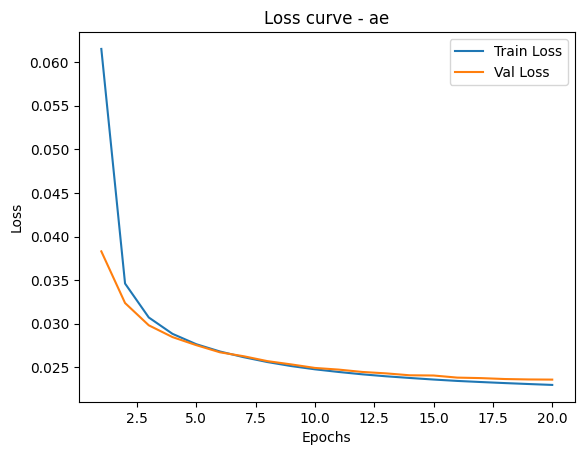


=== Training VAE ===
vae Epoch 01 | Train: 0.0996 (R:0.0865 KL:0.0131) | Val: 0.0834
vae Epoch 02 | Train: 0.0793 (R:0.0594 KL:0.0199) | Val: 0.0776
vae Epoch 03 | Train: 0.0760 (R:0.0542 KL:0.0218) | Val: 0.0755
vae Epoch 04 | Train: 0.0745 (R:0.0519 KL:0.0226) | Val: 0.0744
vae Epoch 05 | Train: 0.0736 (R:0.0508 KL:0.0229) | Val: 0.0738
vae Epoch 06 | Train: 0.0731 (R:0.0501 KL:0.0230) | Val: 0.0732
vae Epoch 07 | Train: 0.0726 (R:0.0495 KL:0.0230) | Val: 0.0728
vae Epoch 08 | Train: 0.0722 (R:0.0491 KL:0.0231) | Val: 0.0726
vae Epoch 09 | Train: 0.0718 (R:0.0487 KL:0.0231) | Val: 0.0721
vae Epoch 10 | Train: 0.0716 (R:0.0484 KL:0.0232) | Val: 0.0719
vae Epoch 11 | Train: 0.0713 (R:0.0481 KL:0.0232) | Val: 0.0717
vae Epoch 12 | Train: 0.0712 (R:0.0480 KL:0.0232) | Val: 0.0715
vae Epoch 13 | Train: 0.0710 (R:0.0478 KL:0.0232) | Val: 0.0713
vae Epoch 14 | Train: 0.0709 (R:0.0477 KL:0.0232) | Val: 0.0712
vae Epoch 15 | Train: 0.0707 (R:0.0475 KL:0.0232) | Val: 0.0711
vae Epoch 16 | Tra

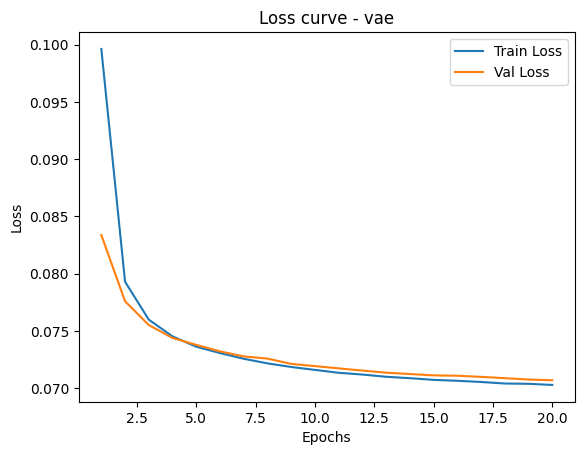


=== Training DAE ===
dae Epoch 01 | Train loss: 0.0723 | Val loss: 0.0491
dae Epoch 02 | Train loss: 0.0450 | Val loss: 0.0426
dae Epoch 03 | Train loss: 0.0406 | Val loss: 0.0394
dae Epoch 04 | Train loss: 0.0383 | Val loss: 0.0377
dae Epoch 05 | Train loss: 0.0370 | Val loss: 0.0367
dae Epoch 06 | Train loss: 0.0361 | Val loss: 0.0360
dae Epoch 07 | Train loss: 0.0355 | Val loss: 0.0353
dae Epoch 08 | Train loss: 0.0349 | Val loss: 0.0349
dae Epoch 09 | Train loss: 0.0345 | Val loss: 0.0345
dae Epoch 10 | Train loss: 0.0341 | Val loss: 0.0342
dae Epoch 11 | Train loss: 0.0338 | Val loss: 0.0339
dae Epoch 12 | Train loss: 0.0336 | Val loss: 0.0338
dae Epoch 13 | Train loss: 0.0334 | Val loss: 0.0335
dae Epoch 14 | Train loss: 0.0332 | Val loss: 0.0335
dae Epoch 15 | Train loss: 0.0330 | Val loss: 0.0332
dae Epoch 16 | Train loss: 0.0329 | Val loss: 0.0330
dae Epoch 17 | Train loss: 0.0327 | Val loss: 0.0329
dae Epoch 18 | Train loss: 0.0326 | Val loss: 0.0328
dae Epoch 19 | Train los

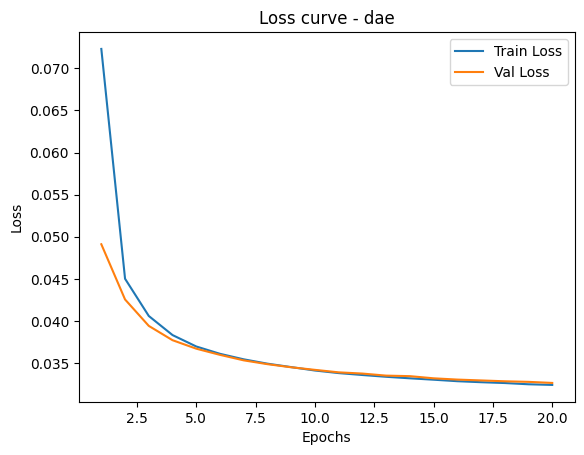

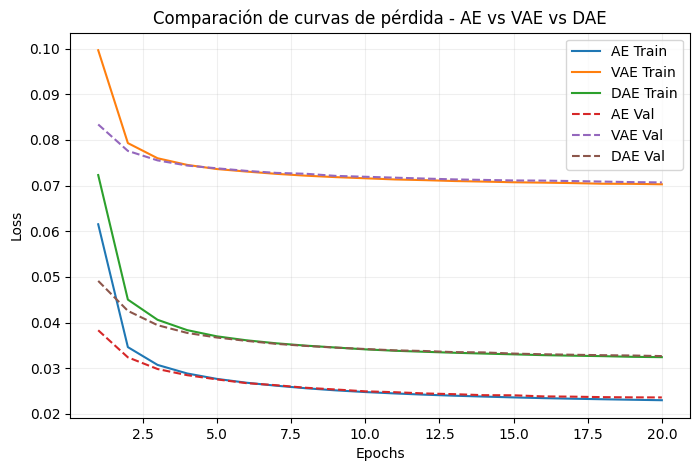

In [ ]:
# ---------------------- 4. ENTRENAMIENTO ----------------------
def reset_torch_seed():
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

def train_and_save(model, name, is_vae=False, is_dae=False):
    train_generator.manual_seed(SEED)  # mismo orden de batches para cada modelo
    optimizer = optim.Adam(model.parameters(), lr=lr)         # usa todos los parámetros del modelo
    train_losses = []
    val_losses = []
    checkpoint_path = os.path.join(save_dir, f'{name}.pth')
    best_val_loss = float('inf')
    best_epoch = 0

    num_epochs = epochs_vae if is_vae else (epochs_dae if is_dae else epochs_ae)
    for epoch in range(1, num_epochs + 1):
        if is_vae:
            train_loss, recon, kl = train_one_epoch_vae(model, train_loader, optimizer)         # entrenamos usando "train_one_epoch_vae"
            val_loss = validate(model, val_loader, is_vae=True)           # validamos
            print(f"{name} Epoch {epoch:02d} | Train: {train_loss:.4f} (R:{recon:.4f} KL:{kl:.4f}) | Val: {val_loss:.4f}")
        else:
            train_loss = train_one_epoch_ae(model, train_loader, optimizer, is_dae)       # si hemos usado DAE entonces is_dae estará a True, si usamos AE estará a False
            val_loss = validate(model, val_loader, is_dae=is_dae)
            print(f"{name} Epoch {epoch:02d} | Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f}")
        train_losses.append(train_loss)         # guardamos las perdidas de entrenamiento
        val_losses.append(val_loss)           # guardamos las pérdidas de validación

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            torch.save(model.state_dict(), checkpoint_path)

    # Recuperamos el checkpoint con menor pérdida de validación.
    model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
    print(f'{name}: restored best checkpoint from epoch {best_epoch} (Val: {best_val_loss:.4f})')

    # Plot loss curve individual
    plt.figure()
    plt.plot(range(1, len(train_losses)+1), train_losses, label='Train Loss')
    plt.plot(range(1, len(val_losses)+1), val_losses, label='Val Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title(f'Loss curve - {name}')
    plt.legend()
    plt.show()

    # devolvemos también las curvas de pérdida
    return model, train_losses, val_losses

# Train the models
print("=== Training AE ===")
reset_torch_seed()
ae = ConvAutoencoder(latent_dim).to(device)
ae, ae_train_losses, ae_val_losses = train_and_save(ae, "ae")

print("\n=== Training VAE ===")
reset_torch_seed()
vae = ConvVAE(latent_dim).to(device)
vae, vae_train_losses, vae_val_losses = train_and_save(vae, "vae", is_vae=True)

print("\n=== Training DAE ===")
reset_torch_seed()
dae = ConvDAE(latent_dim).to(device)
dae, dae_train_losses, dae_val_losses = train_and_save(dae, "dae", is_dae=True)

# Plot conjunto de las 3 curvas (Train y Val)
plt.figure(figsize=(8, 5))

ae_epochs_axis  = range(1, len(ae_train_losses)  + 1)
vae_epochs_axis = range(1, len(vae_train_losses) + 1)
dae_epochs_axis = range(1, len(dae_train_losses) + 1)

# Curvas de entrenamiento
plt.plot(ae_epochs_axis,  ae_train_losses,  label='AE Train')
plt.plot(vae_epochs_axis, vae_train_losses, label='VAE Train')
plt.plot(dae_epochs_axis, dae_train_losses, label='DAE Train')

# Curvas de validación (líneas discontinuas)
plt.plot(ae_epochs_axis,  ae_val_losses,  '--', label='AE Val')
plt.plot(vae_epochs_axis, vae_val_losses, '--', label='VAE Val')
plt.plot(dae_epochs_axis, dae_val_losses, '--', label='DAE Val')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Comparación de curvas de pérdida - AE vs VAE vs DAE')
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()


7. Visualization of Reconstructions

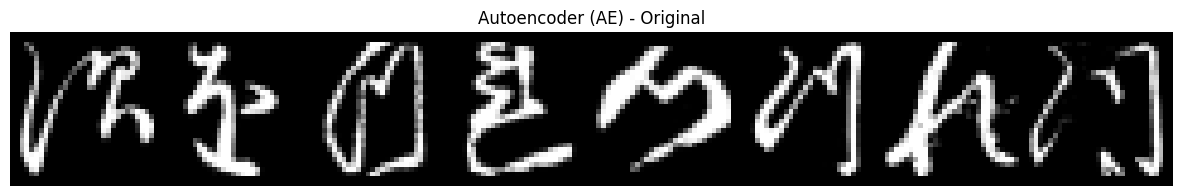

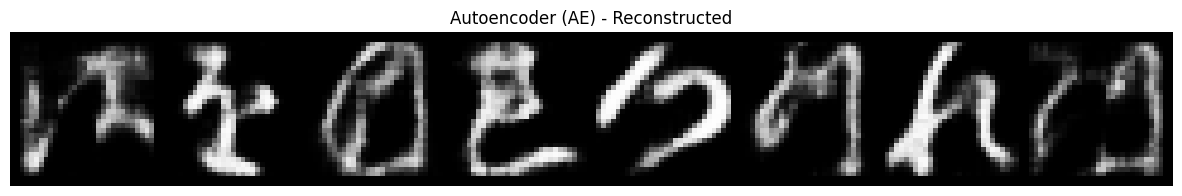

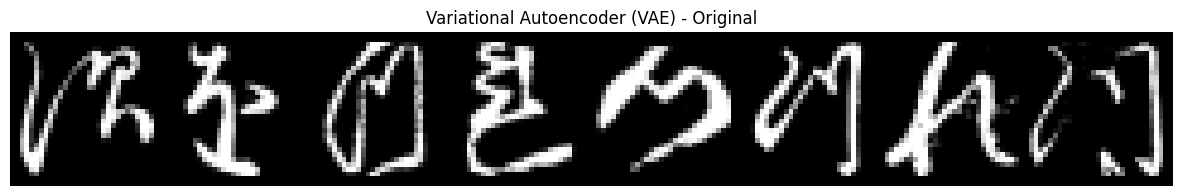

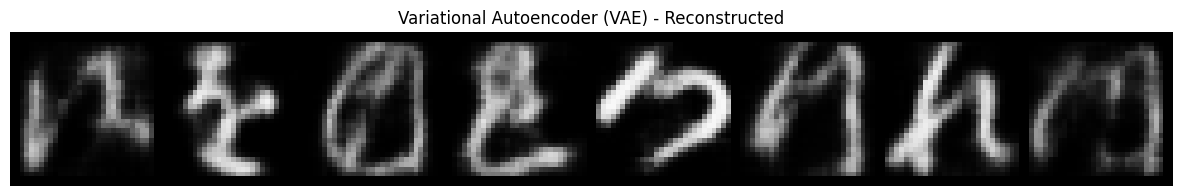

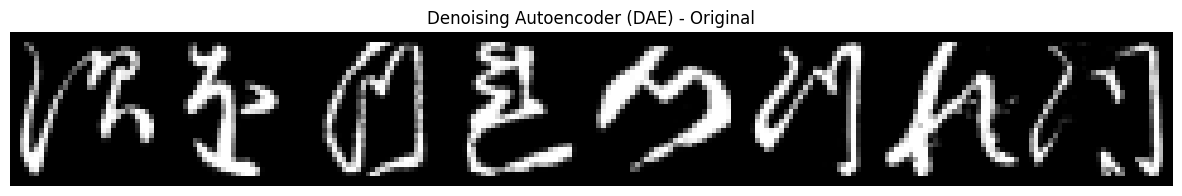

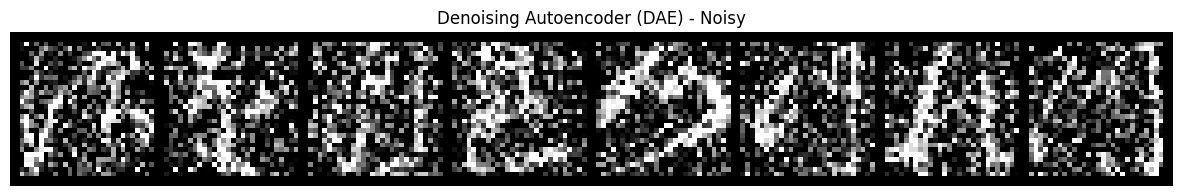

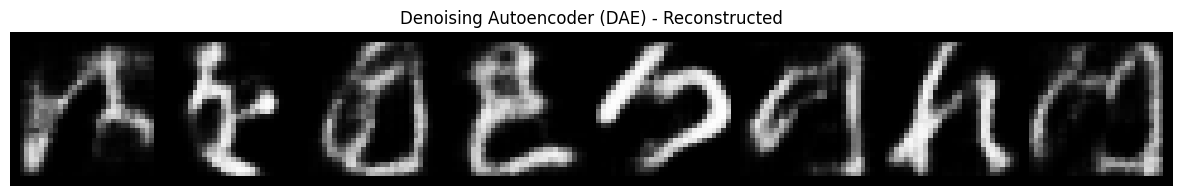

In [ ]:
# ---------------------- 5. RECONSTRUCCIONES ----------------------
def show_reconstructions(model, loader, title, is_vae=False, is_dae=False, n_images=8):
    model.eval()        # desactiva cosas como dropout / batchnorm en modo entrenamiento
    viz_generator = torch.Generator(device=device).manual_seed(SEED)
    with torch.no_grad():         # no guarda gradientes (no vas a entrenar, solo inferir). Más rápido y menos memoria
        data, _ = next(iter(loader))      # iterador de imagenes
        data = data[:n_images].to(device)       # cogemos las ocho primeras
        if is_dae:          # para DAE tenemos que comparar: ['Original', 'Noisy', 'Reconstructed']
            noisy = add_noise(data, noise_factor, generator=viz_generator)
            recon, _ = model(noisy)
            grids = [make_grid(data, nrow=n_images), make_grid(noisy, nrow=n_images), make_grid(recon, nrow=n_images)]      # hacemos un grid de imagenes de las 8 en una sola fila
            sub_titles = ['Original', 'Noisy', 'Reconstructed']
        else:     # para VAE y AE comparamos solamente la original y la reconstruida
            if is_vae:
                # Para comparar reconstrucciones usamos la media posterior (mu), no una muestra aleatoria.
                mu, _ = model.encode(data)
                recon = model.decode(mu)
            else:
                recon, _ = model(data)
            grids = [make_grid(data, nrow=n_images), make_grid(recon, nrow=n_images)]
            sub_titles = ['Original', 'Reconstructed']

        for i, grid in enumerate(grids):
            plt.figure(figsize=(15, 3))
            plt.imshow(grid.permute(1, 2, 0).cpu().numpy())
            plt.title(f"{title} - {sub_titles[i]}")
            plt.axis('off')
            plt.show()

# Esta función sirve para ver visualmente cómo trabaja cada modelo:
  # En el AE/VAE: comparar imagen original vs reconstruida.
  # En el DAE: ver original → con ruido → reconstruida (denoised).

show_reconstructions(ae, test_loader, "Autoencoder (AE)")
show_reconstructions(vae, test_loader, "Variational Autoencoder (VAE)", is_vae=True)
show_reconstructions(dae, test_loader, "Denoising Autoencoder (DAE)", is_dae=True)

8. t-SNE of Latent Space

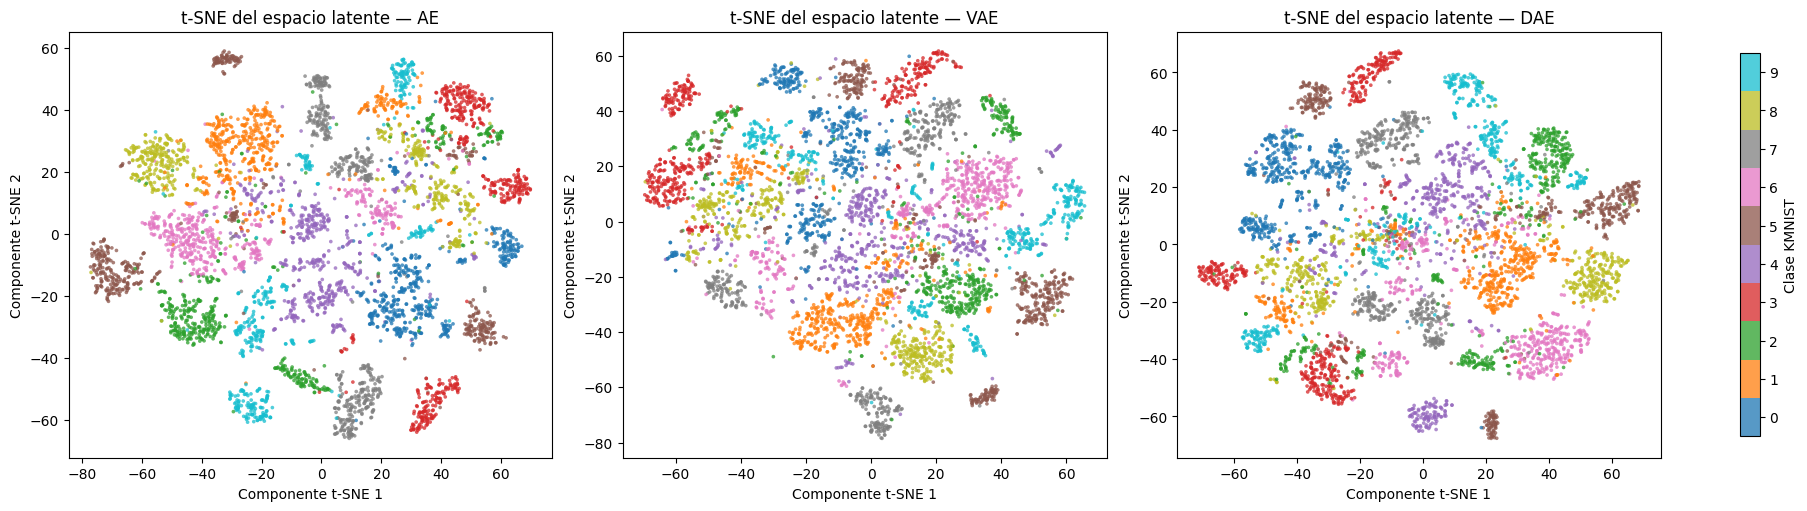

In [ ]:
# ---------------------- 6. t-SNE CORREGIDO ----------------------
from sklearn.preprocessing import StandardScaler

MAX_TSNE_SAMPLES = 5000
TSNE_PERPLEXITY = 30

def extract_latents(model, loader, max_samples, is_vae=False):
    """Extrae cada vector latente junto con la etiqueta de su misma imagen."""
    latent_batches = []
    label_batches = []
    collected = 0
    model.eval()

    with torch.inference_mode():
        for data, target in loader:
            remaining = max_samples - collected
            if remaining <= 0:
                break

            data = data[:remaining].to(device)
            target = target[:remaining]
            encoded = model.encode(data)
            latent = encoded[0] if is_vae else encoded  # En VAE usamos mu.

            latent_batches.append(latent.cpu())
            label_batches.append(target.cpu())
            collected += data.size(0)

    latents = torch.cat(latent_batches).numpy()
    labels = torch.cat(label_batches).numpy()
    return latents, labels

# test_loader no usa shuffle: los tres modelos reciben las mismas 5000 imágenes.
model_specs = {
    'AE': (ae, False),
    'VAE': (vae, True),
    'DAE': (dae, False),
}
latent_spaces = {}
common_labels = None

for name, (model, is_vae) in model_specs.items():
    latents, labels = extract_latents(
        model, test_loader, MAX_TSNE_SAMPLES, is_vae=is_vae
    )
    if common_labels is None:
        common_labels = labels
    elif not np.array_equal(common_labels, labels):
        raise RuntimeError('Las muestras o etiquetas de t-SNE no están alineadas.')
    latent_spaces[name] = latents

if not 0 < TSNE_PERPLEXITY < len(common_labels):
    raise ValueError('TSNE_PERPLEXITY debe ser menor que el número de muestras.')

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
tsne_results = {}
scatter = None

for ax, (name, latents) in zip(axes, latent_spaces.items()):
    if not np.isfinite(latents).all():
        raise ValueError(f'El espacio latente de {name} contiene NaN o infinitos.')

    # La escala del código latente es arbitraria; estandarizamos antes de medir distancias.
    scaled_latents = StandardScaler().fit_transform(latents)
    projection = TSNE(
        n_components=2,
        perplexity=TSNE_PERPLEXITY,
        init='pca',
        learning_rate='auto',
        random_state=SEED,
    ).fit_transform(scaled_latents)
    tsne_results[name] = projection

    scatter = ax.scatter(
        projection[:, 0], projection[:, 1],
        c=common_labels, cmap='tab10', vmin=-0.5, vmax=9.5,
        s=7, alpha=0.75, linewidths=0,
    )
    ax.set_title(f't-SNE del espacio latente — {name}')
    ax.set_xlabel('Componente t-SNE 1')
    ax.set_ylabel('Componente t-SNE 2')

colorbar = fig.colorbar(scatter, ax=axes, ticks=range(10), shrink=0.9)
colorbar.set_label('Clase KMNIST')
plt.show()

# Importante: t-SNE conserva vecindarios locales. La posición, orientación y
# tamaño absoluto de los grupos no deben compararse entre paneles.

9. Transfer Learning: Classification

=== Transfer Learning - Classification ===
AE Encoder Epoch 01 | Train loss: 0.6753 | Val loss: 0.3513
AE Encoder Epoch 02 | Train loss: 0.3668 | Val loss: 0.2710
AE Encoder Epoch 03 | Train loss: 0.3104 | Val loss: 0.2355
AE Encoder Epoch 04 | Train loss: 0.2788 | Val loss: 0.2188
AE Encoder Epoch 05 | Train loss: 0.2591 | Val loss: 0.2048
AE Encoder Epoch 06 | Train loss: 0.2468 | Val loss: 0.1939
AE Encoder Epoch 07 | Train loss: 0.2342 | Val loss: 0.1861
AE Encoder Epoch 08 | Train loss: 0.2283 | Val loss: 0.1796
AE Encoder Epoch 09 | Train loss: 0.2201 | Val loss: 0.1757
AE Encoder Epoch 10 | Train loss: 0.2173 | Val loss: 0.1723
AE Encoder Epoch 11 | Train loss: 0.2120 | Val loss: 0.1709
AE Encoder Epoch 12 | Train loss: 0.2050 | Val loss: 0.1689
AE Encoder Epoch 13 | Train loss: 0.2039 | Val loss: 0.1648
AE Encoder Epoch 14 | Train loss: 0.1971 | Val loss: 0.1647
AE Encoder Epoch 15 | Train loss: 0.2010 | Val loss: 0.1610
AE Encoder Epoch 16 | Train loss: 0.1982 | Val loss: 0.16

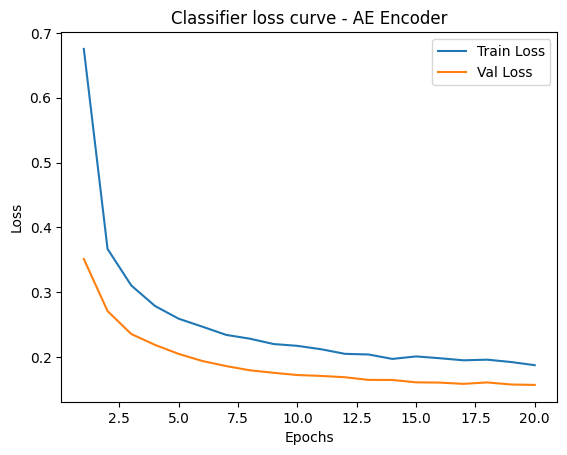

==== AE Encoder Evaluation Results ====
{'acc': 0.8913, 'prec': 0.8924771466829486, 'rec': 0.8913, 'f1': 0.8913038785946252, 'mCA': np.float64(0.8913), 'cm': array([[921,   4,   1,   2,  25,  12,   4,  16,  11,   4],
       [  4, 860,  23,   1,  16,   4,  47,   3,  24,  18],
       [ 10,  19, 839,  43,   7,  10,  19,  14,  16,  23],
       [  2,   7,  27, 942,   1,   6,   6,   3,   4,   2],
       [ 25,  14,  10,  12, 868,   8,  20,  11,  23,   9],
       [  6,  13,  43,  15,  12, 878,  11,   5,  12,   5],
       [  3,   7,  34,   2,  16,   4, 927,   4,   0,   3],
       [ 16,   8,  11,   4,  16,   3,  38, 856,  24,  24],
       [  8,  20,   8,  36,   2,   6,   9,   2, 909,   0],
       [  5,  12,  20,   8,  10,   1,   9,  10,  12, 913]])}


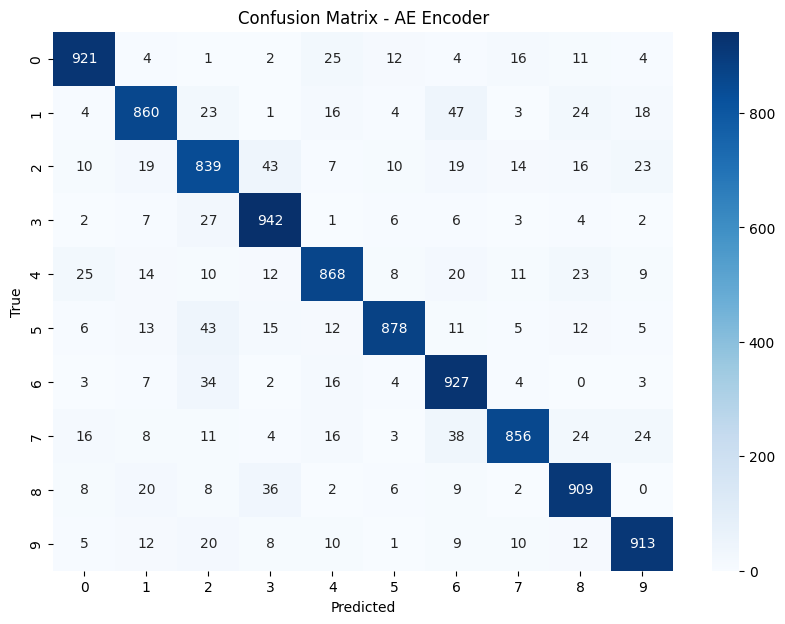

VAE Encoder Epoch 01 | Train loss: 0.9543 | Val loss: 0.5011
VAE Encoder Epoch 02 | Train loss: 0.4840 | Val loss: 0.3689
VAE Encoder Epoch 03 | Train loss: 0.4022 | Val loss: 0.3130
VAE Encoder Epoch 04 | Train loss: 0.3553 | Val loss: 0.2819
VAE Encoder Epoch 05 | Train loss: 0.3266 | Val loss: 0.2590
VAE Encoder Epoch 06 | Train loss: 0.3089 | Val loss: 0.2472
VAE Encoder Epoch 07 | Train loss: 0.2930 | Val loss: 0.2361
VAE Encoder Epoch 08 | Train loss: 0.2844 | Val loss: 0.2264
VAE Encoder Epoch 09 | Train loss: 0.2733 | Val loss: 0.2197
VAE Encoder Epoch 10 | Train loss: 0.2677 | Val loss: 0.2148
VAE Encoder Epoch 11 | Train loss: 0.2602 | Val loss: 0.2096
VAE Encoder Epoch 12 | Train loss: 0.2518 | Val loss: 0.2054
VAE Encoder Epoch 13 | Train loss: 0.2465 | Val loss: 0.2028
VAE Encoder Epoch 14 | Train loss: 0.2413 | Val loss: 0.2007
VAE Encoder Epoch 15 | Train loss: 0.2377 | Val loss: 0.1977
VAE Encoder Epoch 16 | Train loss: 0.2353 | Val loss: 0.1956
VAE Encoder Epoch 17 | T

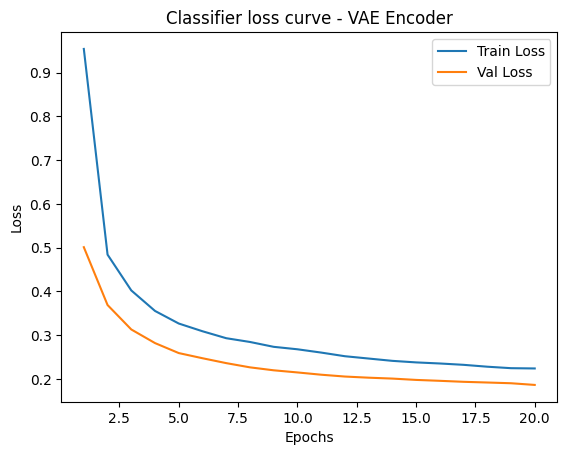

==== VAE Encoder Evaluation Results ====
{'acc': 0.8789, 'prec': 0.8809351680687344, 'rec': 0.8789, 'f1': 0.878997062442572, 'mCA': np.float64(0.8789), 'cm': array([[922,   2,   0,   2,  21,  13,   5,  23,  12,   0],
       [  6, 833,  30,   2,  17,  11,  46,   5,  22,  28],
       [  9,  16, 846,  40,  11,  11,  30,   9,  16,  12],
       [  2,  10,  34, 933,   2,   6,   3,   2,   4,   4],
       [ 31,  20,  15,  13, 851,   7,  17,   9,  27,  10],
       [  7,  12,  72,  12,   9, 848,  21,   1,  15,   3],
       [  4,   8,  27,   8,  16,   4, 925,   2,   5,   1],
       [ 10,   5,  13,   2,  28,   5,  26, 842,  39,  30],
       [  6,  18,  10,  42,   1,   5,  14,   2, 900,   2],
       [  4,  11,  13,   5,  35,   2,  15,  12,  14, 889]])}


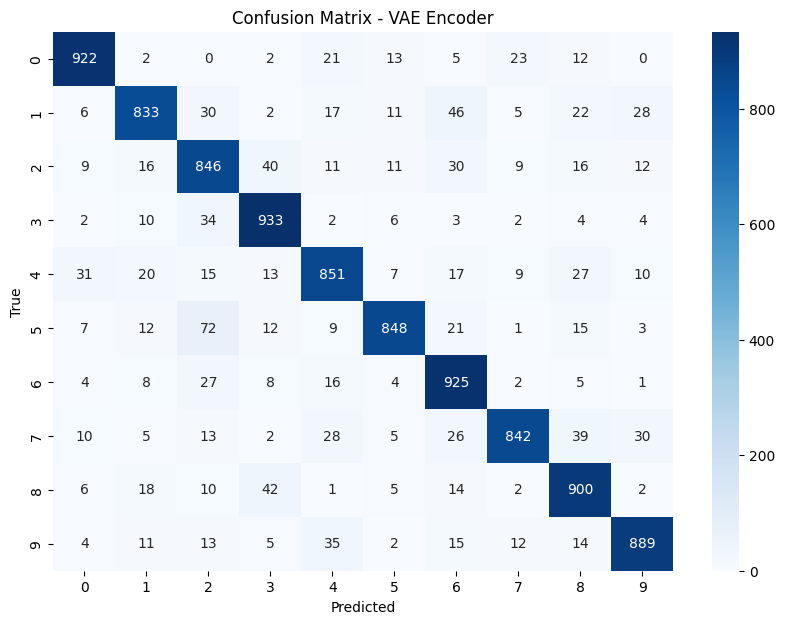

DAE Encoder Epoch 01 | Train loss: 0.7063 | Val loss: 0.3830
DAE Encoder Epoch 02 | Train loss: 0.3980 | Val loss: 0.3017
DAE Encoder Epoch 03 | Train loss: 0.3428 | Val loss: 0.2692
DAE Encoder Epoch 04 | Train loss: 0.3093 | Val loss: 0.2509
DAE Encoder Epoch 05 | Train loss: 0.2901 | Val loss: 0.2332
DAE Encoder Epoch 06 | Train loss: 0.2786 | Val loss: 0.2265
DAE Encoder Epoch 07 | Train loss: 0.2649 | Val loss: 0.2175
DAE Encoder Epoch 08 | Train loss: 0.2593 | Val loss: 0.2101
DAE Encoder Epoch 09 | Train loss: 0.2510 | Val loss: 0.2046
DAE Encoder Epoch 10 | Train loss: 0.2501 | Val loss: 0.2027
DAE Encoder Epoch 11 | Train loss: 0.2420 | Val loss: 0.1985
DAE Encoder Epoch 12 | Train loss: 0.2372 | Val loss: 0.1994
DAE Encoder Epoch 13 | Train loss: 0.2338 | Val loss: 0.1945
DAE Encoder Epoch 14 | Train loss: 0.2290 | Val loss: 0.1950
DAE Encoder Epoch 15 | Train loss: 0.2282 | Val loss: 0.1924
DAE Encoder Epoch 16 | Train loss: 0.2265 | Val loss: 0.1909
DAE Encoder Epoch 17 | T

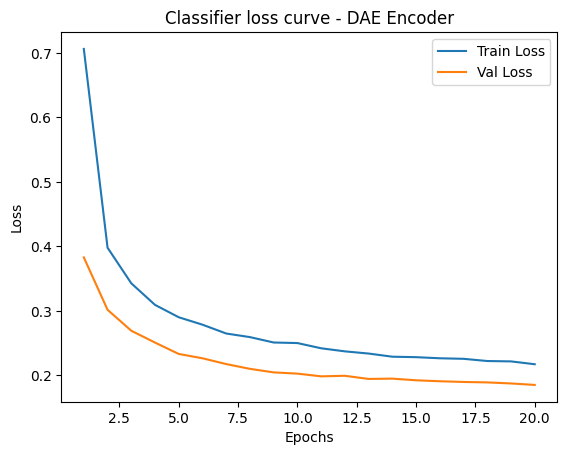

==== DAE Encoder Evaluation Results ====
{'acc': 0.8726, 'prec': 0.8745948177788275, 'rec': 0.8726, 'f1': 0.8727254631267136, 'mCA': np.float64(0.8726), 'cm': array([[884,   6,   0,   1,  38,  12,   4,  24,  26,   5],
       [  5, 842,  24,   2,  29,  15,  49,   4,  17,  13],
       [ 10,  17, 822,  42,  10,  13,  28,  14,  20,  24],
       [  1,   9,  31, 933,   2,   7,   3,   2,   8,   4],
       [ 19,  23,   9,  13, 871,   6,  13,   8,  32,   6],
       [  3,  19,  65,  20,  11, 841,  19,   3,  10,   9],
       [  3,   9,  33,  15,  11,   8, 906,   3,   6,   6],
       [ 10,   4,  10,   7,  34,   6,  36, 836,  26,  31],
       [  6,  15,   5,  34,   4,   4,  10,   7, 911,   4],
       [  3,  25,  28,   4,  23,   2,   6,   6,  23, 880]])}


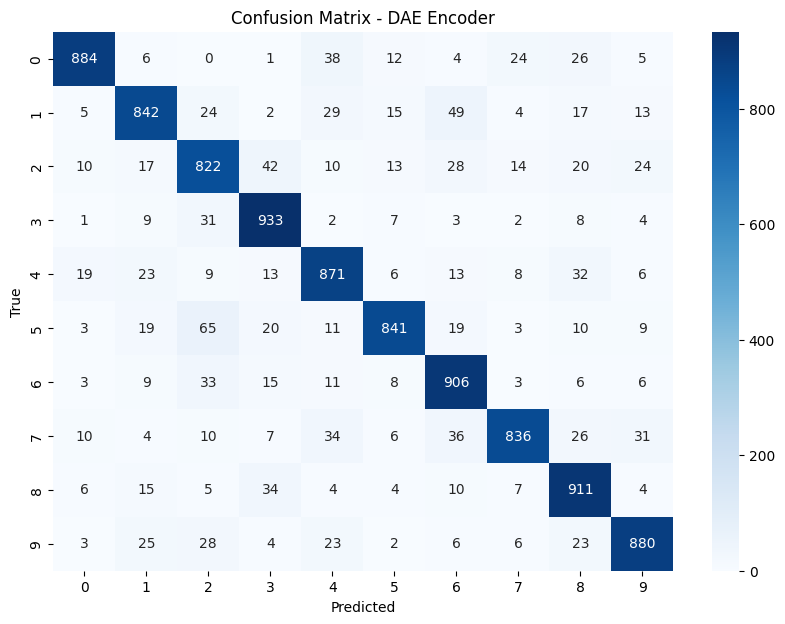

Resumen Transfer Learning:
AE  -> Acc: 0.8913, Prec: 0.8925, Rec: 0.8913, F1: 0.8913
VAE -> Acc: 0.8789, Prec: 0.8809, Rec: 0.8789, F1: 0.8790
DAE -> Acc: 0.8726, Prec: 0.8746, Rec: 0.8726, F1: 0.8727


In [ ]:
# ---------------------- 7. TRANSFER LEARNING ----------------------
class EncoderClassifier(nn.Module):
    def __init__(self, encoder, latent_dim, num_classes=10):        # 10 clases
        super().__init__()
        self.encoder = encoder

        # self.classifier = nn.Linear(latent_dim, num_classes)

        # Clasificador más potente: capa oculta + ReLU + Dropout
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, 128),       # una capa oculta
            nn.ReLU(),
            nn.Dropout(p=0.3),                # <-- dropout para reducir sobreajuste
            nn.Linear(128, num_classes)
        )

        # Congelar el encoder (solo se entrena el clasificador)
        for param in self.encoder.parameters():
            param.requires_grad = False

    def forward(self, x):
        # Para AE y DAE: encoder.encode(x) devuelve z
        # Para VAE: encoder.encode(x) devuelve (mu, logvar) -> nos quedamos con mu
        z = self.encoder.encode(x)
        if isinstance(z, tuple):          # caso VAE --> si z es una tupla
            z = z[0]                      # solo coge mu si estamos en el caso VAE

        logits = self.classifier(z)
        return logits


def train_classifier(clf_model, name):
    reset_torch_seed()
    train_generator.manual_seed(SEED)
    criterion = nn.CrossEntropyLoss()         # Función de pérdida --> estándar para clasificación multiclase
    optimizer = optim.Adam(clf_model.classifier.parameters(), lr=lr)          # No se pasan clf_model.parameters(), solo los de classifier

    train_losses = []
    val_losses = []
    checkpoint_name = name.lower().replace(' ', '_') + '_classifier.pth'
    checkpoint_path = os.path.join(save_dir, checkpoint_name)
    best_val_loss = float('inf')
    best_epoch = 0

    for epoch in range(1, epochs_clf + 1):
        # ---- TRAIN ----
        clf_model.train()
        clf_model.encoder.eval()  # el encoder congelado siempre permanece en evaluación
        total_train_loss = 0.0
        for data, target in train_loader:
            data, target = data.to(device), target.to(device)
            logits = clf_model(data)
            loss = criterion(logits, target)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item() * data.size(0)
        avg_train_loss = total_train_loss / len(train_loader.dataset)

        # ---- VALIDATION ----
        clf_model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for data, target in val_loader:
                data, target = data.to(device), target.to(device)
                logits = clf_model(data)
                loss = criterion(logits, target)
                total_val_loss += loss.item() * data.size(0)
        avg_val_loss = total_val_loss / len(val_loader.dataset)

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_epoch = epoch
            torch.save(clf_model.state_dict(), checkpoint_path)

        print(f"{name} Epoch {epoch:02d} | Train loss: {avg_train_loss:.4f} | Val loss: {avg_val_loss:.4f}")

    clf_model.load_state_dict(
        torch.load(checkpoint_path, map_location=device, weights_only=True)
    )
    print(f'{name}: restored best classifier from epoch {best_epoch} (Val: {best_val_loss:.4f})')

    # Curva de pérdidas del clasificador
    plt.figure()
    plt.plot(range(1, len(train_losses)+1), train_losses, label='Train Loss')
    plt.plot(range(1, len(val_losses)+1), val_losses, label='Val Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title(f'Classifier loss curve - {name}')
    plt.legend()
    plt.show()

    # Evaluación final de clasificación sobre test
    results = evaluate_model(clf_model, test_loader, device)
    print(f"==== {name} Evaluation Results ====")
    print(results)

    # Plot confusion matrix like in Assignment 1
    cm = results['cm']
    plt.figure(figsize=(10, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')      # matriz de confusión bonita
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

    return results


print("=== Transfer Learning - Classification ===")
# AE Classifier
ae.load_state_dict(torch.load(os.path.join(save_dir, 'ae.pth'), map_location=device, weights_only=True))        # cargamos el mejor modelo
reset_torch_seed()
clf_ae = EncoderClassifier(ae, latent_dim).to(device)       # ajustamos sus pesos
results_ae = train_classifier(clf_ae, "AE Encoder")         # lo testeamos en test (transfer learning)

# VAE Classifier
vae.load_state_dict(torch.load(os.path.join(save_dir, 'vae.pth'), map_location=device, weights_only=True))
reset_torch_seed()
clf_vae = EncoderClassifier(vae, latent_dim).to(device)
results_vae = train_classifier(clf_vae, "VAE Encoder")

# DAE Classifier
dae.load_state_dict(torch.load(os.path.join(save_dir, 'dae.pth'), map_location=device, weights_only=True))
reset_torch_seed()
clf_dae = EncoderClassifier(dae, latent_dim).to(device)
results_dae = train_classifier(clf_dae, "DAE Encoder")

# Summary
print("Resumen Transfer Learning:")
print(f"AE  -> Acc: {results_ae['acc']:.4f}, Prec: {results_ae['prec']:.4f}, Rec: {results_ae['rec']:.4f}, F1: {results_ae['f1']:.4f}")
print(f"VAE -> Acc: {results_vae['acc']:.4f}, Prec: {results_vae['prec']:.4f}, Rec: {results_vae['rec']:.4f}, F1: {results_vae['f1']:.4f}")
print(f"DAE -> Acc: {results_dae['acc']:.4f}, Prec: {results_dae['prec']:.4f}, Rec: {results_dae['rec']:.4f}, F1: {results_dae['f1']:.4f}")




---





---



# Assignment 2 Part 2
# **Object Detection**
1.  Download the RGB Dataset and annotate the frames containing humans. For the annotation process, there are many platforms and tools available online, in particular CVAT3 and Roboflow4. These are platforms that you can use to streamline the annotation process. However, since these platforms contain options that are unavailable to free users, you can implement your own version of a 2D bounding box annotator using python and opencv2 (check cv2.setMouseCallback and cv2.imshow). An example is shown in Fig. 2. To simplify the annotation process, you can implement an auto labeling/annotation pipeline:
*   Label a subset of your images manually (maybe 50–100 images) to get a baseline;
*   Train a YOLO detector on that labeled subset;
*   Run the model on the unlabeled images (generate 2D bounding boxes);
*   Remove wrong annotations and refine each bounding box’s position and shape;
*   Retrain the model on the expanded dataset;
*   Repeat until all humans are annotated (go to step 3), if no improvement hand-annotate the missing bounding boxes.
For each image, a corresponding label file (.txt) must be created, where each row will represent an object (bounding box) with the following structure:
object_class_id normalized_center_x normalized_center_y normalized_width normalized_height

2.  Organize the dataset in the following structure, use the frames 0-499 for training (create a small split if you want a validation set) and 500-599 for testing.
3.  Prepare the data configuration (yaml file to set DATASETFILE) files required to run/train the YOLO model on the provided set of images. For that, you should set the defined split for training/testing, respectively; DATASETFILE example (data/APA2025.yaml):
path: A2PartII_APA2025 train: images/train val: images/val
test: images/test
nc: 1
names: [Humans]
4.  Select three different detection architectures available on the YOLO Ultralytics webpage(e.g.,YOLOv8s, YOLOv10s, YOLOv11s) and train the network. Train the networks from scratch during 50 epochs (it will take a while).
To import and train a YOLO model, select the YOLO architecture (MODEL NAME) and give it the DATASETFILE file to train the model.
5.  Train the same YOLO architectures, using as a starting point the pretrained checkpoints provided online5 (also use 50 epochs).
6.  Gather the loss curves for all training conditions. Evaluate all the models in the training set. To generate the curves and metrics for a specific model use:
model = YOLO('PATH_TO_MODEL.pt') metrics = model.val(split='test')








In [1]:
# ---------------------- PART 2: DRIVE SETUP ----------------------
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

from pathlib import Path
import os
import shutil
import subprocess
import sys
import urllib.request
import zipfile

# Version fixed so future executions use the same Ultralytics API.
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q',
    'ultralytics==8.4.137', 'gdown==5.2.0'
])

DRIVE_ROOT = Path('/content/drive/MyDrive')
if not DRIVE_ROOT.is_dir():
    raise RuntimeError(
        'Google Drive is not mounted correctly. Authorize drive.mount and rerun this cell.'
    )
INPUT_DIR = DRIVE_ROOT / 'A2PartII_APA2025_inputs'
PROJECT_DIR = DRIVE_ROOT / 'A2PartII_APA2025'
RUNS_PROJECT = PROJECT_DIR / 'runs' / 'detect'
DATASET_RAR = INPUT_DIR / 'dataset.rar'
LABELS_ZIP = INPUT_DIR / 'labels.zip'
DATASET_FILE = PROJECT_DIR / 'APA2025.yaml'

INPUT_DIR.mkdir(parents=True, exist_ok=True)
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
RUNS_PROJECT.mkdir(parents=True, exist_ok=True)

if not PROJECT_DIR.is_dir():
    raise OSError(f'Could not create the project directory: {PROJECT_DIR}')

print(f'Input files: {INPUT_DIR}')
print(f'Dataset and outputs: {PROJECT_DIR}')
print('Drive setup completed successfully.')

Mounted at /content/drive
Input files: /content/drive/MyDrive/A2PartII_APA2025_inputs
Dataset and outputs: /content/drive/MyDrive/A2PartII_APA2025
Drive setup completed successfully.


In [2]:
# ---------------------- DOWNLOAD REQUIRED FILES ----------------------
import gdown

if 'PROJECT_DIR' not in globals() or not PROJECT_DIR.is_dir():
    raise RuntimeError(
        'Run the PART 2: DRIVE SETUP cell immediately above before this cell.'
    )

DATASET_FILE_ID = '1n2IDe_eKauoJ0W0lmaZisaXegKZTJ8OO'
LABELS_URL = (
    'https://raw.githubusercontent.com/franfgv9/data-science-portfolio/main/'
    '06-applied-deep-learning/02-autoencoders-and-yolo/labels.zip'
)

INPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_RAR.exists() or DATASET_RAR.stat().st_size == 0:
    print('Downloading dataset.rar to Google Drive...')
    downloaded = gdown.download(
        id=DATASET_FILE_ID, output=str(DATASET_RAR), quiet=False
    )
    if downloaded is None or not DATASET_RAR.exists() or DATASET_RAR.stat().st_size == 0:
        raise RuntimeError(
            'dataset.rar could not be downloaded. Check access to the Google Drive file.'
        )
else:
    print(f'Using existing file: {DATASET_RAR}')

if not LABELS_ZIP.exists() or LABELS_ZIP.stat().st_size == 0:
    print('Downloading labels.zip from the project repository...')
    urllib.request.urlretrieve(LABELS_URL, LABELS_ZIP)
else:
    print(f'Using existing file: {LABELS_ZIP}')

if not zipfile.is_zipfile(LABELS_ZIP):
    raise RuntimeError(f'The downloaded labels file is not a valid ZIP: {LABELS_ZIP}')

print(f'dataset.rar: {DATASET_RAR.stat().st_size / 1024**2:.1f} MB')
print(f'labels.zip: {LABELS_ZIP.stat().st_size / 1024**2:.1f} MB')

Using existing file: /content/drive/MyDrive/A2PartII_APA2025_inputs/dataset.rar
Using existing file: /content/drive/MyDrive/A2PartII_APA2025_inputs/labels.zip
dataset.rar: 224.8 MB
labels.zip: 0.2 MB


In [3]:
# ---------------------- EXTRACT DATASET AND LABELS ----------------------
SPLITS = ('train', 'val', 'test')
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
SPLIT_INDICES = {
    'train': range(0, 450),
    'val': range(450, 500),
    'test': range(500, 600),
}
EXPECTED_IMAGE_COUNTS = {split: len(indices) for split, indices in SPLIT_INDICES.items()}

def count_images(folder):
    if not folder.is_dir():
        return 0
    return sum(
        path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
        for path in folder.iterdir()
    )

def find_dataset_root(search_root):
    """Find a non-empty YOLO layout: root/images/{train,val,test}."""
    if search_root is None or not Path(search_root).is_dir():
        return None
    candidates = []
    for images_dir in Path(search_root).rglob('images'):
        counts = {split: count_images(images_dir / split) for split in SPLITS}
        if counts == EXPECTED_IMAGE_COUNTS:
            candidates.append((images_dir.parent, sum(counts.values())))
    if not candidates:
        return None
    # Prefer the candidate with most images, then the shallowest path.
    candidates.sort(key=lambda item: (-item[1], len(item[0].parts), str(item[0])))
    return candidates[0][0]

def find_flat_image_source(search_root):
    """Find the extracted folder containing frames 000000 through 000599."""
    expected_stems = {f'{index:06d}' for index in range(600)}
    images_by_parent = {}
    for path in Path(search_root).rglob('*'):
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES:
            images_by_parent.setdefault(path.parent, {})[path.stem] = path
    candidates = [
        (parent, files)
        for parent, files in images_by_parent.items()
        if expected_stems.issubset(files)
    ]
    if not candidates:
        return None
    candidates.sort(key=lambda item: (len(item[0].parts), str(item[0])))
    return candidates[0]

def build_yolo_image_layout(flat_files, destination_root):
    """Copy the flat frames into the train/val/test layout expected by YOLO."""
    for split, indices in SPLIT_INDICES.items():
        destination_dir = destination_root / 'images' / split
        destination_dir.mkdir(parents=True, exist_ok=True)
        copied = 0
        for index in indices:
            stem = f'{index:06d}'
            source = flat_files[stem]
            destination = destination_dir / source.name
            if not destination.exists() or destination.stat().st_size != source.stat().st_size:
                shutil.copy2(source, destination)
                copied += 1
        print(
            f'{split}: {len(indices)} images prepared in {destination_dir} '
            f'({copied} copied this execution)'
        )

if 'PROJECT_DIR' not in globals() or not PROJECT_DIR.is_dir():
    raise RuntimeError(
        'PROJECT_DIR does not exist. Run PART 2: DRIVE SETUP and DOWNLOAD REQUIRED FILES first.'
    )
if 'DATASET_RAR' not in globals() or not DATASET_RAR.is_file():
    raise FileNotFoundError(
        'dataset.rar is missing. Run the DOWNLOAD REQUIRED FILES cell first.'
    )
if 'LABELS_ZIP' not in globals() or not LABELS_ZIP.is_file():
    raise FileNotFoundError(
        'labels.zip is missing. Run the DOWNLOAD REQUIRED FILES cell first.'
    )

# Never reuse a stale None value from an earlier failed execution.
DATASET_ROOT = find_dataset_root(PROJECT_DIR)
flat_source = find_flat_image_source(PROJECT_DIR) if DATASET_ROOT is None else None

# Extract only when neither an organized dataset nor the 600 flat frames exist.
if DATASET_ROOT is None and flat_source is None:
    if shutil.which('unrar') is None:
        subprocess.check_call(['apt-get', '-qq', 'update'])
        subprocess.check_call(['apt-get', '-qq', 'install', '-y', 'unrar'])

    with DATASET_RAR.open('rb') as handle:
        rar_signature = handle.read(8)
    if not rar_signature.startswith(b'Rar!\x1a\x07'):
        raise RuntimeError(
            f'{DATASET_RAR} is not a valid RAR archive. Delete it and rerun the download cell.'
        )

    print(f'Extracting images into {PROJECT_DIR}...')
    try:
        subprocess.check_call([
            'unrar', 'x', '-o+', '-Y', str(DATASET_RAR), str(PROJECT_DIR) + os.sep
        ])
    except subprocess.CalledProcessError as error:
        raise RuntimeError(
            'dataset.rar could not be extracted. The archive may be incomplete or damaged.'
        ) from error
    DATASET_ROOT = find_dataset_root(PROJECT_DIR)
    flat_source = find_flat_image_source(PROJECT_DIR) if DATASET_ROOT is None else None

# Minnie's RAR stores the frames in one flat directory. Build the YOLO splits from
# their numeric names while retaining the original extracted images.
if DATASET_ROOT is None and flat_source is not None:
    flat_dir, flat_files = flat_source
    print(f'Flat image directory detected at: {flat_dir}')
    DATASET_ROOT = PROJECT_DIR / 'yolo_dataset'
    build_yolo_image_layout(flat_files, DATASET_ROOT)
    DATASET_ROOT = find_dataset_root(DATASET_ROOT)

if DATASET_ROOT is None:
    visible_dirs = [
        str(path.relative_to(PROJECT_DIR))
        for path in PROJECT_DIR.rglob('*') if path.is_dir()
    ][:50]
    image_samples = [
        str(path.relative_to(PROJECT_DIR))
        for path in PROJECT_DIR.rglob('*')
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
    ][:10]
    raise FileNotFoundError(
        'Extraction finished, but no non-empty images/train, images/val and images/test '
        f'layout was found inside {PROJECT_DIR}. '
        f'First directories: {visible_dirs}. First images: {image_samples}'
    )

print(f'Dataset root detected at: {DATASET_ROOT}')

# Always install the verified annotations next to the detected images folder.
print(f'Extracting verified labels into {DATASET_ROOT}...')
with zipfile.ZipFile(LABELS_ZIP) as archive:
    for member in archive.infolist():
        if not member.filename.endswith('.cache'):
            archive.extract(member, DATASET_ROOT)

# Minnie's cache files contain paths from her environment; Ultralytics must rebuild them.
for cache_file in (DATASET_ROOT / 'labels').glob('*.cache'):
    cache_file.unlink()
    print(f'Removed stale cache: {cache_file.name}')

Flat image directory detected at: /content/drive/MyDrive/A2PartII_APA2025/A2PartII_APA2025
train: 450 images prepared in /content/drive/MyDrive/A2PartII_APA2025/yolo_dataset/images/train (450 copied this execution)
val: 50 images prepared in /content/drive/MyDrive/A2PartII_APA2025/yolo_dataset/images/val (50 copied this execution)
test: 100 images prepared in /content/drive/MyDrive/A2PartII_APA2025/yolo_dataset/images/test (100 copied this execution)
Dataset root detected at: /content/drive/MyDrive/A2PartII_APA2025/yolo_dataset
Extracting verified labels into /content/drive/MyDrive/A2PartII_APA2025/yolo_dataset...


In [4]:
# ---------------------- VERIFY DATASET STRUCTURE ----------------------
EXPECTED_COUNTS = {'train': 450, 'val': 50, 'test': 100}
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

if 'PROJECT_DIR' not in globals() or not PROJECT_DIR.is_dir():
    raise RuntimeError('Run all Part 2 cells from PART 2: DRIVE SETUP in order.')

if 'DATASET_ROOT' not in globals() or DATASET_ROOT is None:
    DATASET_ROOT = find_dataset_root(PROJECT_DIR)
if DATASET_ROOT is None:
    raise FileNotFoundError(
        'The dataset root was not found. Rerun EXTRACT DATASET AND LABELS and read its diagnostic.'
    )
DATASET_ROOT = Path(DATASET_ROOT)

for split, expected_count in EXPECTED_COUNTS.items():
    image_dir = DATASET_ROOT / 'images' / split
    label_dir = DATASET_ROOT / 'labels' / split
    if not image_dir.is_dir() or not label_dir.is_dir():
        raise FileNotFoundError(
            f'Missing images/{split} or labels/{split} inside {DATASET_ROOT}'
        )

    image_stems = {
        path.stem for path in image_dir.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
    }
    label_stems = {path.stem for path in label_dir.glob('*.txt')}

    if len(image_stems) != expected_count or len(label_stems) != expected_count:
        raise ValueError(
            f'{split}: expected {expected_count} images and labels, found '
            f'{len(image_stems)} images and {len(label_stems)} labels.'
        )
    if image_stems != label_stems:
        missing_labels = sorted(image_stems - label_stems)[:5]
        missing_images = sorted(label_stems - image_stems)[:5]
        raise ValueError(
            f'{split}: image/label names do not match. '
            f'Missing labels: {missing_labels}; missing images: {missing_images}'
        )

    print(f'{split}: {len(image_stems)} image-label pairs OK')

train: 450 image-label pairs OK
val: 50 image-label pairs OK
test: 100 image-label pairs OK


In [5]:
# ---------------------- CREATE YOLO DATA YAML ----------------------
import yaml

dataset_config = {
    'path': str(DATASET_ROOT),
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'nc': 1,
    'names': ['human'],
}
with DATASET_FILE.open('w', encoding='utf-8') as handle:
    yaml.safe_dump(dataset_config, handle, sort_keys=False)

print(DATASET_FILE.read_text(encoding='utf-8'))

path: /content/drive/MyDrive/A2PartII_APA2025/yolo_dataset
train: images/train
val: images/val
test: images/test
nc: 1
names:
- human



In [6]:
# ---------------------- YOLO TRAINING CONFIGURATION ----------------------
import torch
import ultralytics
from ultralytics import YOLO

EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 16
YOLO_SEED = 42
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
MODEL_NAMES = ('yolov8s', 'yolov9s', 'yolov10s')

print(f'Ultralytics version: {ultralytics.__version__}')
print(f'Training device: {DEVICE}')
print(f'All runs will be saved directly in: {RUNS_PROJECT}')
if DEVICE == 'cpu':
    print('WARNING: select a GPU runtime in Colab before training six models.')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics version: 8.4.137
Training device: 0
All runs will be saved directly in: /content/drive/MyDrive/A2PartII_APA2025/runs/detect


In [7]:
# Choose which experiments to run. Six trainings at 50 epochs can take several hours.
TRAIN_FROM_SCRATCH = False
TRAIN_PRETRAINED = True

COMMON_TRAIN_ARGS = {
    'data': str(DATASET_FILE),
    'epochs': EPOCHS,
    'imgsz': IMAGE_SIZE,
    'batch': BATCH_SIZE,
    'device': DEVICE,
    'project': str(RUNS_PROJECT),
    'exist_ok': True,
    'seed': YOLO_SEED,
    'deterministic': True,
    'plots': True,
}

def completed_epochs(run_dir):
    results_csv = run_dir / 'results.csv'
    if not results_csv.exists():
        return 0
    with results_csv.open(encoding='utf-8') as handle:
        return max(sum(1 for line in handle if line.strip()) - 1, 0)

def train_or_resume(model_source, run_name):
    run_dir = RUNS_PROJECT / run_name
    last_checkpoint = run_dir / 'weights' / 'last.pt'
    epochs_done = completed_epochs(run_dir)

    if epochs_done >= EPOCHS:
        print(f'{run_name}: already completed ({epochs_done} epochs); skipped.')
        return
    if last_checkpoint.exists():
        print(f'{run_name}: resuming from epoch {epochs_done}.')
        YOLO(str(last_checkpoint)).train(resume=True)
        return

    YOLO(model_source).train(name=run_name, **COMMON_TRAIN_ARGS)

print('Experiments configured:')
print(f'  From scratch: {TRAIN_FROM_SCRATCH}')
print(f'  Pretrained:   {TRAIN_PRETRAINED}')

Experiments configured:
  From scratch: False
  Pretrained:   True


In [8]:
# ---------------------- TRAIN FROM SCRATCH ----------------------
if TRAIN_FROM_SCRATCH:
    print(f'Starting training from scratch for {EPOCHS} epochs')
    for model_name in MODEL_NAMES:
        architecture = f'{model_name}.yaml'
        run_name = f'{model_name}_scratch'
        print(f'\nTraining {architecture} -> {run_name}')
        train_or_resume(architecture, run_name)
else:
    print('Scratch training skipped.')

Scratch training skipped.


In [9]:
# ---------------------- TRAIN FROM PRETRAINED WEIGHTS ----------------------
if TRAIN_PRETRAINED:
    print(f'Starting pretrained training for {EPOCHS} epochs')
    for model_name in MODEL_NAMES:
        checkpoint = f'{model_name}.pt'
        run_name = f'{model_name}_pretrained'
        print(f'\nTraining {checkpoint} -> {run_name}')
        train_or_resume(checkpoint, run_name)
else:
    print('Pretrained training skipped.')


Starting pretrained training for 50 epochs

Training yolov8s.pt -> yolov8s_pretrained
Ultralytics 8.4.137 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/A2PartII_APA2025/APA2025.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode

In [10]:
# ---------------------- EVALUATE ALL BEST CHECKPOINTS ON TEST ----------------------
import pandas as pd

MODEL_RUN_NAMES = [
    f'{model_name}_{training_type}'
    for model_name in MODEL_NAMES
    for training_type in ('scratch', 'pretrained')
]
final_metrics = []

for run_name in MODEL_RUN_NAMES:
    model_path = RUNS_PROJECT / run_name / 'weights' / 'best.pt'
    if not model_path.exists():
        print(f'SKIPPED: checkpoint not found: {model_path}')
        continue

    print(f'\nEvaluating {run_name}: {model_path}')
    model = YOLO(str(model_path))
    metrics = model.val(
        data=str(DATASET_FILE),
        split='test',
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        project=str(RUNS_PROJECT),
        name=f'{run_name}_test',
        exist_ok=True,
        plots=True,
    )
    final_metrics.append({
        'Model_Name': run_name,
        'mAP50_Test': float(metrics.box.map50),
        'mAP50-95_Test': float(metrics.box.map),
        'Precision_Test': float(metrics.box.mp),
        'Recall_Test': float(metrics.box.mr),
    })

if not final_metrics:
    raise RuntimeError('No trained best.pt checkpoints were found for evaluation.')

metrics_df = pd.DataFrame(final_metrics).sort_values(
    'mAP50-95_Test', ascending=False
)
metrics_csv = PROJECT_DIR / 'test_metrics.csv'
metrics_df.to_csv(metrics_csv, index=False)
display(metrics_df)
print(f'Metrics saved to: {metrics_csv}')

SKIPPED: checkpoint not found: /content/drive/MyDrive/A2PartII_APA2025/runs/detect/yolov8s_scratch/weights/best.pt

Evaluating yolov8s_pretrained: /content/drive/MyDrive/A2PartII_APA2025/runs/detect/yolov8s_pretrained/weights/best.pt
Ultralytics 8.4.137 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.3 ms, read: 71.3±84.4 MB/s, size: 402.8 KB)
val: Scanning /content/drive/MyDrive/A2PartII_APA2025/yolo_dataset/labels/test... 100 images, 13 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 212.3it/s 0.5s
val: New cache created: /content/drive/MyDrive/A2PartII_APA2025/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.0it/s 3.5s
                   all        100        259      0.857      0.739      0.826       0.45
Speed: 7.9ms preprocess, 9.5ms inference, 0.1ms

,Model_Name,mAP50_Test,mAP50-95_Test,Precision_Test,Recall_Test
0,yolov8s_pretrained,0.826406,0.449723,0.856688,0.738572
1,yolov9s_pretrained,0.823687,0.427815,0.804879,0.756757
2,yolov10s_pretrained,0.793993,0.409385,0.782902,0.710105


Metrics saved to: /content/drive/MyDrive/A2PartII_APA2025/test_metrics.csv


In [11]:
# No move command is needed: training and validation outputs were written to Drive.
print('Part 2 completed.')
print(f'Dataset YAML: {DATASET_FILE}')
print(f'Training/validation runs: {RUNS_PROJECT}')
print(f'Summary metrics: {PROJECT_DIR / "test_metrics.csv"}')


Part 2 completed.
Dataset YAML: /content/drive/MyDrive/A2PartII_APA2025/APA2025.yaml
Training/validation runs: /content/drive/MyDrive/A2PartII_APA2025/runs/detect
Summary metrics: /content/drive/MyDrive/A2PartII_APA2025/test_metrics.csv
